# Task 1 : Data Cleaning and Formatting

In [2]:
import pandas as pd
import numpy as np

In [3]:
df=pd.read_csv("Morgan_Stainley_Financial_Data.csv")

In [4]:
df.head() # --> Shows the first five rows to understand the dataset structure .

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,78,CUST1223,ACC33287,Credit,Withdrawal,Savings Account,Firm E,South,Manager 4,06-01-2023,81300.425190,40843.56193,0.330474,484,13
1,21,CUST8266,ACC58667,Savings,Withdrawal,Credit Card,Firm A,South,Manager 2,17-02-2023,9269.640373,61183.03953,0.089688,836,18
2,176,CUST9420,ACC99117,Credit,Transfer,Home Loan,Firm A,East,Manager 1,13-09-2023,28138.552650,85460.13405,0.340010,451,25
3,167,CUST5253,ACC10117,Loan,Payment,Mutual Fund,Firm D,Central,Manager 1,28-05-2024,83943.556980,100525.35900,0.605383,487,13
4,46,CUST1223,ACC74631,Savings,Deposit,Credit Card,Firm A,East,Manager 4,12-05-2023,77104.456470,57425.69930,1.042441,393,10


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   TransactionID      800 non-null    int64  
 1   CustomerID         800 non-null    object 
 2   AccountID          800 non-null    object 
 3   AccountType        800 non-null    object 
 4   TransactionType    800 non-null    object 
 5   Product            800 non-null    object 
 6   Firm               800 non-null    object 
 7   Region             800 non-null    object 
 8   Manager            800 non-null    object 
 9   TransactionDate    800 non-null    object 
 10  TransactionAmount  800 non-null    float64
 11  AccountBalance     800 non-null    float64
 12  RiskScore          800 non-null    float64
 13  CreditRating       800 non-null    int64  
 14  TenureMonths       800 non-null    int64  
dtypes: float64(3), int64(3), object(9)
memory usage: 93.9+ KB


In [6]:
# Check the missing values .

df.isnull().sum()

TransactionID        0
CustomerID           0
AccountID            0
AccountType          0
TransactionType      0
Product              0
Firm                 0
Region               0
Manager              0
TransactionDate      0
TransactionAmount    0
AccountBalance       0
RiskScore            0
CreditRating         0
TenureMonths         0
dtype: int64

In [7]:
# Check the duplicate Records

df.duplicated().sum()


np.int64(0)

In [8]:
df=df.drop_duplicates()

In [9]:
df

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths
0,78,CUST1223,ACC33287,Credit,Withdrawal,Savings Account,Firm E,South,Manager 4,06-01-2023,81300.425190,40843.56193,0.330474,484,13
1,21,CUST8266,ACC58667,Savings,Withdrawal,Credit Card,Firm A,South,Manager 2,17-02-2023,9269.640373,61183.03953,0.089688,836,18
2,176,CUST9420,ACC99117,Credit,Transfer,Home Loan,Firm A,East,Manager 1,13-09-2023,28138.552650,85460.13405,0.340010,451,25
3,167,CUST5253,ACC10117,Loan,Payment,Mutual Fund,Firm D,Central,Manager 1,28-05-2024,83943.556980,100525.35900,0.605383,487,13
4,46,CUST1223,ACC74631,Savings,Deposit,Credit Card,Firm A,East,Manager 4,12-05-2023,77104.456470,57425.69930,1.042441,393,10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,131,CUST3015,ACC96277,Savings,Transfer,Home Loan,Firm A,North,Manager 1,01-01-2024,74309.497130,61659.15894,0.425553,372,23
796,158,CUST5558,ACC80131,Current,Transfer,Mutual Fund,Firm E,West,Manager 1,12-05-2023,45859.598950,103267.73470,0.642004,401,104
797,132,CUST7345,ACC37688,Savings,Transfer,Personal Loan,Firm C,East,Manager 1,22-03-2024,458.484909,59361.15542,0.410000,667,139
798,28,CUST8028,ACC61827,Savings,Transfer,Credit Card,Firm A,South,Manager 3,21-03-2024,31344.178850,168048.03330,0.546988,407,30


In [10]:
# Check the Financial Columns .

df[["TransactionAmount","AccountBalance"]].dtypes

TransactionAmount    float64
AccountBalance       float64
dtype: object

In [11]:
# Convert TransactionDate to Date Date format .

# pd.to_datetime() ---> Convert the values into datetime format .
# errors="coerce" ---> Change the invalid dates into NaT (Not a time) insted of causing an error.

df["TransactionDate"]=pd.to_datetime(df["TransactionDate"],errors="coerce")

In [12]:
df["TransactionDate"].head() # ---> Vrify date fromat .

0   2023-06-01
1          NaT
2          NaT
3          NaT
4   2023-12-05
Name: TransactionDate, dtype: datetime64[ns]

In [13]:
# Standardize Text columns  .

# str.strip() ----> Removes extra spaces .

# str.lower() ---> Convert text to Title case .

text_columns=["AccountType","TransactionType","Product","Firm","Region","Manager"]

for col in text_columns:
  df[col]=df[col].str.strip().str.title()

In [14]:
text_columns

['AccountType', 'TransactionType', 'Product', 'Firm', 'Region', 'Manager']

In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   TransactionID      800 non-null    int64         
 1   CustomerID         800 non-null    object        
 2   AccountID          800 non-null    object        
 3   AccountType        800 non-null    object        
 4   TransactionType    800 non-null    object        
 5   Product            800 non-null    object        
 6   Firm               800 non-null    object        
 7   Region             800 non-null    object        
 8   Manager            800 non-null    object        
 9   TransactionDate    312 non-null    datetime64[ns]
 10  TransactionAmount  800 non-null    float64       
 11  AccountBalance     800 non-null    float64       
 12  RiskScore          800 non-null    float64       
 13  CreditRating       800 non-null    int64         
 14  TenureMont

#  Task 2 : Descriptive Transaction Analysis  . 

In [17]:
print(df.columns)

Index(['TransactionID', 'CustomerID', 'AccountID', 'AccountType',
       'TransactionType', 'Product', 'Firm', 'Region', 'Manager',
       'TransactionDate', 'TransactionAmount', 'AccountBalance', 'RiskScore',
       'CreditRating', 'TenureMonths'],
      dtype='object')


In [18]:
#   Convert Transaction Date to datetime.

df["TransactionDate"]=pd.to_datetime(df["TransactionDate"], format="%d-%m-%Y")

In [19]:
df["TransactionDate"]

0     2023-06-01
1            NaT
2            NaT
3            NaT
4     2023-12-05
         ...    
795   2024-01-01
796   2023-12-05
797          NaT
798          NaT
799          NaT
Name: TransactionDate, Length: 800, dtype: datetime64[ns]

In [20]:
# Create month and year columns .

df["Month"] = df["TransactionDate"].dt.month_name()

df["Year"] = df["TransactionDate"].dt.year

In [21]:
df["Month"]


0          June
1           NaN
2           NaN
3           NaN
4      December
         ...   
795     January
796    December
797         NaN
798         NaN
799         NaN
Name: Month, Length: 800, dtype: object

In [22]:
df["Year"]

0      2023.0
1         NaN
2         NaN
3         NaN
4      2023.0
        ...  
795    2024.0
796    2023.0
797       NaN
798       NaN
799       NaN
Name: Year, Length: 800, dtype: float64

In [23]:
print(df["TransactionType"].unique())

['Withdrawal' 'Transfer' 'Payment' 'Deposit']


In [24]:
# Calculate Monthly credits .

# Deposit vs Credit .


monthly_credit= (df[df["TransactionType"]=="Deposit"]
.groupby("Month")["TransactionAmount"].sum())

In [25]:
monthly_credit

Month
April        369306.296340
August       159863.128420
December     388479.557490
February     321905.313680
January      236498.733640
July         119669.499800
June         567702.944594
March        238005.718930
May          297498.874010
November     500418.472960
October      392129.532030
September    295963.292219
Name: TransactionAmount, dtype: float64

In [26]:
# Withdrawal as Debit

monthly_debit = (df[df["TransactionType"]=="Withdrawal"].groupby("Month")["TransactionAmount"].sum())

In [27]:
monthly_debit

Month
April        315445.653711
August       644497.479680
December     622717.625146
February     380010.823690
January      252471.501970
July         128684.194640
June         847416.662830
March        147595.196500
May          165045.987940
November     576270.256760
October      405047.617450
September    146235.155634
Name: TransactionAmount, dtype: float64

In [28]:
monthly_net=monthly_credit - monthly_debit

In [29]:
monthly_net #----> All months showed positive net inflows , with February having the highest net transaction volume .

Month
April         53860.642629
August      -484634.351260
December    -234238.067656
February     -58105.510010
January      -15972.768330
July          -9014.694840
June        -279713.718236
March         90410.522430
May          132452.886070
November     -75851.783800
October      -12918.085420
September    149728.136585
Name: TransactionAmount, dtype: float64

In [30]:
# Yealy summary .

yearly_summary = df.pivot_table(index="Year",columns="TransactionType",values="TransactionAmount",aggfunc="sum")

In [31]:
yearly_summary

TransactionType,Deposit,Payment,Transfer,Withdrawal
Year,,,,
2023.0,2.716096e+06,2.785213e+06,2.800923e+06,2.998893e+06
2024.0,1.171346e+06,1.179510e+06,1.676654e+06,1.632545e+06


In [32]:
import matplotlib.pyplot as plt

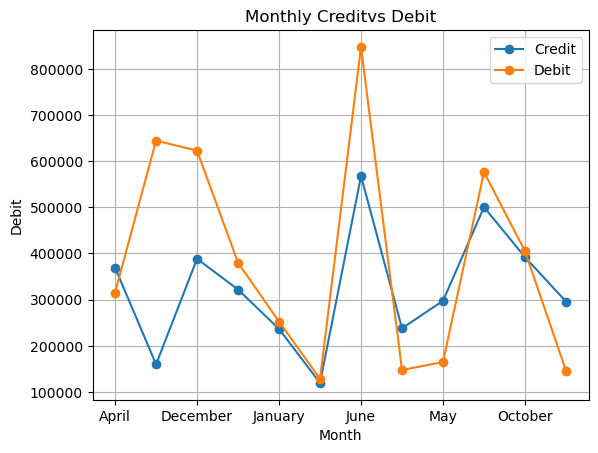

In [33]:
# Plot Credit vs Debit 

# -----> Credit transaction remained above debit transactions throghout the period . 


monthly_credit.plot(marker="o",label="Credit")

monthly_debit.plot(marker="o",label="Debit")


plt.title("Monthly Creditvs Debit")
plt.xlabel("Month")
plt.ylabel("Debit")
plt.legend()
plt.grid(True)

In [34]:
# ----> Top Performing Accounts 



# Total Deposits (Credit)
credit = (
    df[df["TransactionType"] == "Deposit"]
    .groupby("AccountID")["TransactionAmount"]
    .sum()
)

# Total Money Out (Debit)
debit = (
    df[df["TransactionType"].isin(["Withdrawal", "Transfer", "Payment"])]
    .groupby("AccountID")["TransactionAmount"]
    .sum()
)

# Net Inflow
net = credit.subtract(debit, fill_value=0)

# Top 10 Accounts
top_accounts = net.sort_values(ascending=False).head(10)



In [35]:
top_accounts
 
#----> Higher net inflow indicates better-performing accounts. 

# ----> These accounts cosistently recived more money than they spent.

AccountID
ACC38559    195846.243974
ACC57700    171403.143000
ACC31539    128947.199760
ACC51971    115097.311765
ACC18177    102494.720970
ACC94907     99517.266910
ACC54589     97067.455410
ACC83581     83274.250450
ACC65545     76716.657680
ACC12334     74852.576147
Name: TransactionAmount, dtype: float64

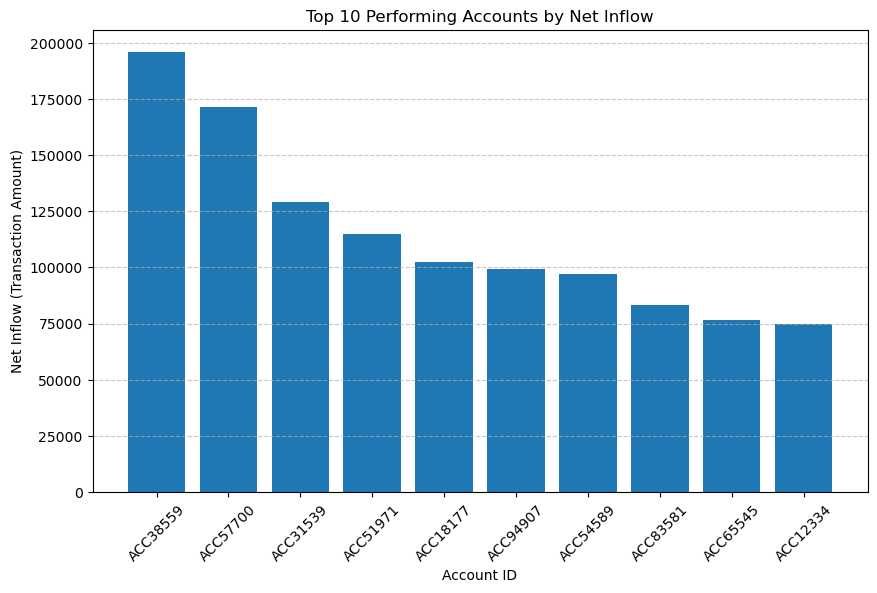

In [36]:
# a bar chart showing the Top 10 Accounts . 

# x-axix :  Top 10 account IDs . 
# Y-axis : Net inflow (deposits - Withdrawals/transfers/payments) . 

# ----> The tallest bar represents the account with the highest positive net inflow . 


plt.figure(figsize=(10,6))

plt.bar(top_accounts.index.astype(str), top_accounts.values)

plt.title("Top 10 Performing Accounts by Net Inflow")
plt.xlabel("Account ID")
plt.ylabel("Net Inflow (Transaction Amount)")
plt.xticks(rotation=45)

plt.grid(axis='y', linestyle='--', alpha=0.7)


plt.show()

In [37]:
# Bottom Performing Accounts . 

bottom_accounts = net.sort_values().head(10)

In [38]:
# Negative values indicates more withdrawals than diposits . 

# -----> These accounts may require financial monitoring due to  persistent net outflows .  


bottom_accounts




AccountID
ACC61926   -693174.040150
ACC10117   -494956.052140
ACC51009   -493622.951140
ACC88449   -458658.991110
ACC19178   -428726.771550
ACC77592   -411152.932010
ACC71426   -408217.398938
ACC23736   -392885.206970
ACC16664   -376020.628670
ACC34431   -368976.601220
Name: TransactionAmount, dtype: float64

In [39]:
# Identify Dormant Accounts . 

df = df.sort_values(["AccountID","TransactionDate"])

df["GapDays"] =(df.groupby("AccountID")["TransactionDate"].diff().dt.days)

dormant = df[df["GapDays"]>=60]

In [40]:
dormant[["AccountID","TransactionDate","GapDays"]]

#  ---> A gap of 60 days or more between consecutive transactions flags an accounts as dormant . 

# ----> Dormant accounts indicate low customer activity and  may require engagement or follow-up . 

,AccountID,TransactionDate,GapDays
753,ACC10117,2024-05-02,390.0
510,ACC11188,2024-05-02,326.0
219,ACC11837,2023-12-01,120.0
61,ACC12334,2024-06-02,264.0
159,ACC13357,2024-06-02,237.0
...,...,...,...
335,ACC95774,2024-08-02,304.0
113,ACC96868,2024-11-06,155.0
518,ACC99549,2023-06-06,62.0
597,ACC99549,2023-12-02,179.0


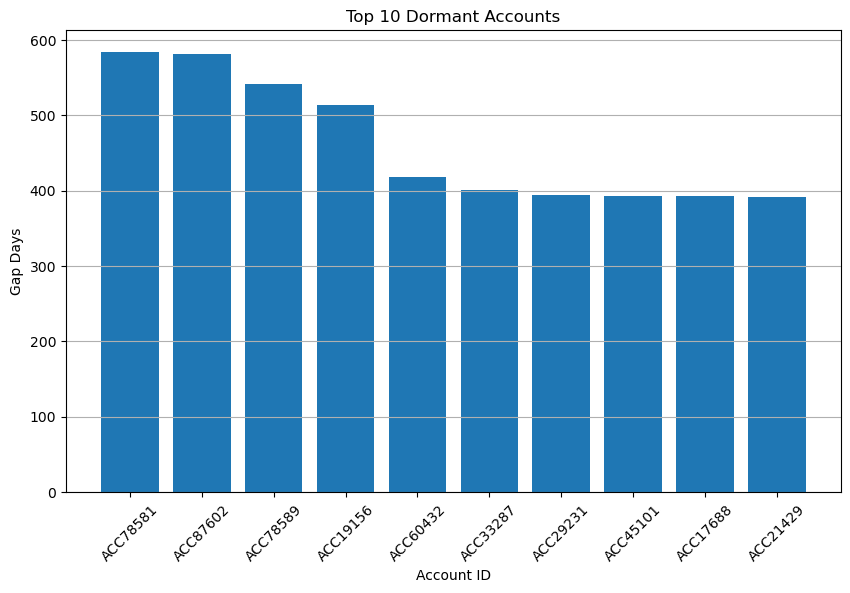

In [41]:
#  bar showing the Top 10 Dormant Accounts . 

top_dormant = dormant.sort_values('GapDays', ascending=False).head(10)

plt.figure(figsize=(10,6))
plt.bar(top_dormant['AccountID'].astype(str), top_dormant['GapDays'])
        

plt.title("Top 10 Dormant Accounts")
plt.xlabel("Account ID") # -----> Accounts IDs . 
plt.ylabel("Gap Days")    # -----> Number of inactive days(GapDays) .
plt.xticks(rotation=45)
plt.grid(axis='y')


plt.show()



# TASK 3 : Customer Profile Building . 

In [43]:
# Group Accounts by Activity level .



# Count transaction for each account 

activity = df.groupby("AccountID").size().reset_index(name='Transaction_count')

# Activity classification 

def activity_level(x):
    if x > 20:
        return "High Activity"
    elif x >= 10:
        return "Medium Activity"

    else: 
        return "Low Activity"




activity["Activity_level"] = activity["Transaction_count"].apply(activity_level)

In [44]:
activity.head()

,AccountID,Transaction_count,Activity_level
0,ACC10117,9,Low Activity
1,ACC10996,8,Low Activity
2,ACC11062,4,Low Activity
3,ACC11188,2,Low Activity
4,ACC11285,5,Low Activity


In [45]:
# Segment customers by Average balance . 

balance = df.groupby('AccountID')['AccountBalance'].mean().reset_index()

balance.rename(columns={'AccountBalance':'Average_Balance'}, inplace=True)

def balance_segment(x):
    if x > 100000:
        return 'High Balance'
    elif x >= 30000:
        return 'Medium Balance'
    else:
        return 'Low Balance'

balance['Balance_Segment'] = balance['Average_Balance'].apply(balance_segment)

balance.head()

,AccountID,Average_Balance,Balance_Segment
0,ACC10117,94082.590727,Medium Balance
1,ACC10996,72517.761136,Medium Balance
2,ACC11062,73541.328302,Medium Balance
3,ACC11188,51359.039950,Medium Balance
4,ACC11285,79923.619870,Medium Balance


In [46]:
print(balance.columns.tolist())
print(balance.head())

['AccountID', 'Average_Balance', 'Balance_Segment']
  AccountID  Average_Balance Balance_Segment
0  ACC10117     94082.590727  Medium Balance
1  ACC10996     72517.761136  Medium Balance
2  ACC11062     73541.328302  Medium Balance
3  ACC11188     51359.039950  Medium Balance
4  ACC11285     79923.619870  Medium Balance


In [47]:
# Segment customers by transaction volume . 

volume = df.groupby("AccountID")["TransactionAmount"].mean().reset_index()

volume.rename( columns={"TransactionAmount": "Average_Transaction"},    inplace=True)
    
    


def volume_segment(x):
    if x > 50000:
        return "High Balance"
    elif x >= 10000:
        return "Medium Balance"
    else:
        return "Low Balance"

volume["Volume_Segment"] = volume["Average_Transaction"].apply(volume_segment)

In [48]:
print(volume.head())

  AccountID  Average_Transaction  Volume_Segment
0  ACC10117         66625.415300    High Balance
1  ACC10996         63343.269757    High Balance
2  ACC11062         61846.052310    High Balance
3  ACC11188         63817.462940    High Balance
4  ACC11285         33863.793906  Medium Balance


In [49]:
# Create the Customer profile . 

customer_profile = activity.merge(balance, on="AccountID")

customer_profile = customer_profile.merge(volume,on="AccountID")
                                  

In [50]:
customer_profile.head()

,AccountID,Transaction_count,Activity_level,Average_Balance,Balance_Segment,Average_Transaction,Volume_Segment
0,ACC10117,9,Low Activity,94082.590727,Medium Balance,66625.415300,High Balance
1,ACC10996,8,Low Activity,72517.761136,Medium Balance,63343.269757,High Balance
2,ACC11062,4,Low Activity,73541.328302,Medium Balance,61846.052310,High Balance
3,ACC11188,2,Low Activity,51359.039950,Medium Balance,63817.462940,High Balance
4,ACC11285,5,Low Activity,79923.619870,Medium Balance,33863.793906,Medium Balance


In [51]:
# High-Net Inflow Accounts . 


# Total Deposit per Account
deposit = ( df[df["TransactionType"].str.lower() == "deposit"].groupby("AccountID")["TransactionAmount"] .sum())
   

# Total Withdrawal per Account
withdrawal = ( df[df["TransactionType"].str.lower() == "withdrawal"] .groupby("AccountID")
    ["TransactionAmount"] .sum())
   


# Net Inflow
net_inflow = deposit.sub(withdrawal, fill_value=0).reset_index()

net_inflow.columns = ["AccountID", "Net_Inflow"]

# Top 10 Accounts
high_net_inflow = net_inflow.sort_values( by="Net_Inflow",ascending=False)
 

In [52]:
print(high_net_inflow.head(10))

    AccountID     Net_Inflow
79   ACC48501  298630.612740
99   ACC57700  250121.858500
61   ACC38559  195846.243974
143  ACC83581  184645.184450
15   ACC18177  174360.269780
1    ACC10996  170489.488060
130  ACC77773  164800.931510
160  ACC95774  159019.925350
94   ACC54589  158664.568530
165  ACC99549  158565.218750


In [53]:
# High_Frequency Low-Balance Accounts.


activity = df.groupby("AccountID")["TransactionID"].count().reset_index()

activity.rename(columns={"TransactionID": "Transaction_count"}, inplace=True)

def activity_level(x):
    if x >= 8:
        return "High Activity"
    elif x >= 4:
        return "Medium Activity"
    else:
        return "Low Activity"

activity["Activity_level"] = activity["Transaction_count"].apply(activity_level)


In [54]:
print(activity.head())

  AccountID  Transaction_count   Activity_level
0  ACC10117                  9    High Activity
1  ACC10996                  8    High Activity
2  ACC11062                  4  Medium Activity
3  ACC11188                  2     Low Activity
4  ACC11285                  5  Medium Activity


In [55]:
customer_profile.head()

,AccountID,Transaction_count,Activity_level,Average_Balance,Balance_Segment,Average_Transaction,Volume_Segment
0,ACC10117,9,Low Activity,94082.590727,Medium Balance,66625.415300,High Balance
1,ACC10996,8,Low Activity,72517.761136,Medium Balance,63343.269757,High Balance
2,ACC11062,4,Low Activity,73541.328302,Medium Balance,61846.052310,High Balance
3,ACC11188,2,Low Activity,51359.039950,Medium Balance,63817.462940,High Balance
4,ACC11285,5,Low Activity,79923.619870,Medium Balance,33863.793906,Medium Balance


In [56]:
# Account with Negative or Near-Zero Balances .


low_balance_accounts = balance[ balance["Average_Balance"] <= 1000]



low_balance_accounts = low_balance_accounts.sort_values(by="Average_Balance")
  


In [57]:
print(low_balance_accounts)

Empty DataFrame
Columns: [AccountID, Average_Balance, Balance_Segment]
Index: []


In [58]:
customer_profile.to_csv("Customer_Profile_csv",index=False)

print("Customer Profile has been saved successfuly.")

Customer Profile has been saved successfuly.


# TASK 4 : Financial Risk  Identification .


In [60]:
#  Track Account with Frequent Large Withdrawals . 

# A large withdrawals is any debit transaction greater than 50000 . 

# An account is flagged if it has 3 or more such withdrawals . 

# Large Withdrawals (Amount > 50000) . 

large_withdrawals = df[
    (df["TransactionType"].str.lower() == "withdrawal") &
    (df["TransactionAmount"].abs() > 50000)
]

# Count Large Withdrawals per Account
withdrawal_count = (
    large_withdrawals.groupby("AccountID")
    .size()
    .reset_index(name="Large_Withdrawal_Count")
)

# Risky Accounts (3 or more large withdrawals)
risky_withdrawals = withdrawal_count[
    withdrawal_count["Large_Withdrawal_Count"] >= 3
]

print(risky_withdrawals)
   

   AccountID  Large_Withdrawal_Count
5   ACC15671                       3
7   ACC19156                       3
14  ACC24070                       3
27  ACC33287                       3
70  ACC77592                       3
72  ACC78178                       3


In [61]:
# Identify Overdraft Accounts 

# ---> Accounts with negative balance are treated as overdraft accounts . 

overdraft_account = df[df["AccountBalance"] <0]

In [62]:
overdraft_account

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths,Month,Year,GapDays
599,19,CUST7730,ACC11837,Current,Withdrawal,Credit Card,Firm E,Central,Manager 1,NaT,33431.99905,-467.139424,0.315078,436,196,NaN,NaN,NaN
350,146,CUST7459,ACC17688,Savings,Deposit,Credit Card,Firm C,East,Manager 3,NaT,30451.57674,-6998.284258,0.478290,464,217,NaN,NaN,NaN
391,159,CUST8318,ACC18177,Savings,Deposit,Savings Account,Firm A,East,Manager 3,NaT,39472.17958,-6158.757250,0.345215,418,140,NaN,NaN,NaN
507,71,CUST1609,ACC19156,Savings,Withdrawal,Savings Account,Firm A,West,Manager 1,2024-11-06,62369.77560,-31233.114930,0.712639,461,188,November,2024.0,514.0
158,190,CUST6292,ACC26940,Current,Transfer,Savings Account,Firm A,South,Manager 2,NaT,86937.69692,-22668.046670,0.699954,417,92,NaN,NaN,NaN
416,76,CUST4595,ACC32212,Savings,Transfer,Personal Loan,Firm B,North,Manager 4,2024-04-02,42862.98663,-28676.452550,0.558000,745,63,April,2024.0,89.0
253,101,CUST1913,ACC34431,Savings,Deposit,Personal Loan,Firm B,North,Manager 2,2024-12-01,62071.84059,-6111.634329,0.392788,547,186,December,2024.0,362.0
733,59,CUST7395,ACC39529,Credit,Withdrawal,Credit Card,Firm E,East,Manager 3,NaT,20588.47104,-8628.929364,0.691175,800,222,NaN,NaN,NaN
224,67,CUST4884,ACC48501,Credit,Payment,Mutual Fund,Firm B,West,Manager 3,NaT,63366.02809,-6629.775977,0.382749,355,42,NaN,NaN,NaN
496,32,CUST2443,ACC49774,Loan,Withdrawal,Home Loan,Firm E,East,Manager 2,NaT,48038.68802,-2135.472998,0.766556,683,26,NaN,NaN,NaN


In [63]:
# Calculate Balance Volatility 

# ----> Balance volatility is measured using the coefficient of vareation (CV) . 


volatility = df.groupby("AccountID")["AccountBalance"].agg(["mean","std"]).reset_index()

volatility["CV"] = volatility["std"]/volatility["mean"]

volatility = volatility.sort_values("CV",ascending=False)

In [64]:
volatility.head()

,AccountID,mean,std,CV
38,ACC26940,7017.436865,41981.613421,5.982471
185,ACC97411,32190.912745,68179.288932,2.117967
152,ACC78589,34171.301430,42257.915468,1.236649
133,ACC70741,56589.212756,67364.539557,1.190413
116,ACC60432,47025.713171,50384.539932,1.071425


In [70]:
print(df["TransactionDate"].isna().sum())

488


In [71]:
missing_dates = df[df["TransactionDate"].isna()]

print(missing_dates)

     TransactionID CustomerID AccountID AccountType TransactionType  \
3              167   CUST5253  ACC10117        Loan         Payment   
58              72   CUST1498  ACC10117     Current         Deposit   
179            125   CUST5174  ACC10117      Credit         Payment   
318            196   CUST1913  ACC10117     Savings        Transfer   
509            127   CUST9528  ACC10117     Savings        Transfer   
..             ...        ...       ...         ...             ...   
758              9   CUST6028  ACC99409     Current         Payment   
65              82   CUST5385  ACC99549        Loan         Deposit   
67             136   CUST4669  ACC99549     Current        Transfer   
231            124   CUST7855  ACC99549     Current        Transfer   
435            128   CUST7388  ACC99549     Savings         Deposit   

             Product    Firm   Region    Manager TransactionDate  \
3        Mutual Fund  Firm D  Central  Manager 1             NaT   
58       Mu

In [72]:
df = df.dropna(subset=["TransactionDate"])

In [73]:
df

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths,Month,Year,GapDays
727,114,CUST8091,ACC10117,Savings,Withdrawal,Credit Card,Firm A,South,Manager 3,2023-04-08,-18353.15647,99972.730020,-0.010665,619,225,April,2023.0,NaN
753,66,CUST6028,ACC10117,Loan,Withdrawal,Home Loan,Firm A,East,Manager 2,2024-05-02,89088.28060,64499.600480,0.273698,337,194,May,2024.0,390.0
655,68,CUST6947,ACC10996,Loan,Payment,Home Loan,Firm C,South,Manager 2,2023-05-02,17518.03652,82155.780970,0.583926,580,210,May,2023.0,NaN
148,67,CUST9666,ACC11062,Current,Transfer,Personal Loan,Firm C,East,Manager 1,2024-12-03,73480.16656,35136.521340,0.576353,507,60,December,2024.0,NaN
561,50,CUST2805,ACC11188,Credit,Withdrawal,Personal Loan,Firm E,East,Manager 3,2023-06-11,70259.20760,44947.089920,0.338871,694,229,June,2023.0,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
264,167,CUST6776,ACC99549,Current,Transfer,Personal Loan,Firm D,West,Manager 1,2023-04-05,83740.76593,42973.403220,0.401151,839,233,April,2023.0,NaN
518,50,CUST4625,ACC99549,Credit,Transfer,Personal Loan,Firm E,North,Manager 3,2023-06-06,72499.16252,105166.597500,0.486469,360,50,June,2023.0,62.0
597,84,CUST7028,ACC99549,Current,Transfer,Mutual Fund,Firm B,West,Manager 3,2023-12-02,27349.31140,261.171238,0.401315,499,85,December,2023.0,179.0
280,51,CUST7933,ACC99549,Current,Withdrawal,Personal Loan,Firm D,East,Manager 4,2024-01-04,53636.57769,93646.968750,0.632746,596,43,January,2024.0,33.0


In [74]:
df["Month"] = df["TransactionDate"].dt.month_name()
df["Year"] = df["TransactionDate"].dt.year

In [75]:
df["Month"]

727       April
753         May
655         May
148    December
561        June
         ...   
264       April
518        June
597    December
280     January
563       April
Name: Month, Length: 312, dtype: object

In [76]:
df["Year"]

727    2023
753    2024
655    2023
148    2024
561    2023
       ... 
264    2023
518    2023
597    2023
280    2024
563    2024
Name: Year, Length: 312, dtype: int32

In [77]:
df["TransactionDate"] = pd.to_datetime(
    df["TransactionDate"],
    errors="coerce"
)

In [80]:
# Detect Anomalies Using IQR . 

# Calculate Quartiles
Q1 = df["TransactionAmount"].quantile(0.25)
Q3 = df["TransactionAmount"].quantile(0.75)


# Calculate IQR
IQR = Q3 - Q1

# Calculate Lower and Upper Limits
lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

# Find Outliers
iqr_outliers = df[ (df["TransactionAmount"] < lower) | (df["TransactionAmount"] > upper)]

In [81]:
iqr_outliers 

,TransactionID,CustomerID,AccountID,AccountType,TransactionType,Product,Firm,Region,Manager,TransactionDate,TransactionAmount,AccountBalance,RiskScore,CreditRating,TenureMonths,Month,Year,GapDays
161,52,CUST4258,ACC35419,Loan,Transfer,Personal Loan,Firm B,Central,Manager 1,2023-07-11,-36173.69555,24563.76881,0.838911,745,29,July,2023,34.0


In [82]:
# Detect Anomalies Using Z-Score . 

from scipy.stats import zscore
import numpy as np


In [84]:
# Calculate Z-score for each transaction amount
df["ZScore"] = zscore(df["TransactionAmount"])

# Find outliers (|Z| > 3)
z_outliers = df[np.abs(df["ZScore"]) > 3]

# Find outliers (|Z| > 3)  
z_outliers = df[np.abs(df["ZScore"]) > 3]

In [85]:
print(z_outliers)

     TransactionID CustomerID AccountID AccountType TransactionType  \
161             52   CUST4258  ACC35419        Loan        Transfer   

           Product    Firm   Region    Manager TransactionDate  \
161  Personal Loan  Firm B  Central  Manager 1      2023-07-11   

     TransactionAmount  AccountBalance  RiskScore  CreditRating  TenureMonths  \
161       -36173.69555     24563.76881   0.838911           745            29   

    Month  Year  GapDays  ZScore  
161  July  2023     34.0 -3.2475  


In [87]:
#  Count the Number of Outliers

print("Number of Z-score Outliers:", len(z_outliers))

Number of Z-score Outliers: 1


# Task 5 :  Visulization 



In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('ggplot')


Text(0, 0.5, 'Count')

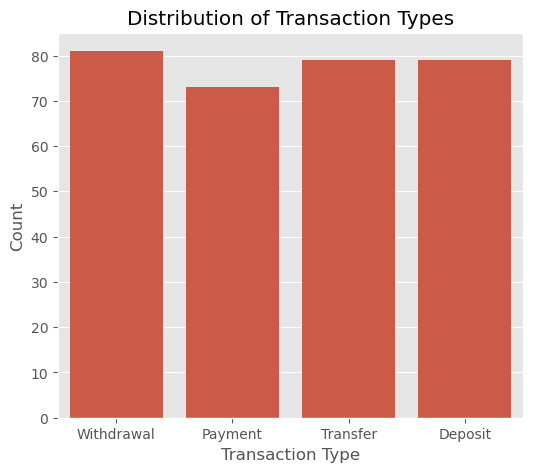

In [92]:
# Distribution of transaction types . 


plt.figure(figsize=(6,5))

sns.countplot(x='TransactionType', data=df)

plt.title("Distribution of Transaction Types")
plt.xlabel("Transaction Type")
plt.ylabel("Count")

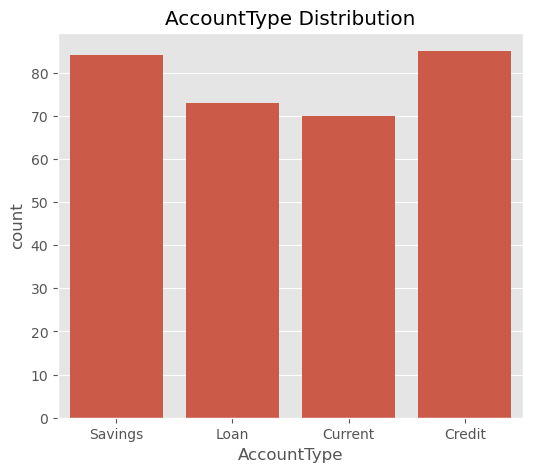

In [96]:
# Distribution of account types . 

plt.figure(figsize=(6,5))

sns.countplot(x="AccountType",data=df)

plt.title("AccountType Distribution")

plt.show()           

           

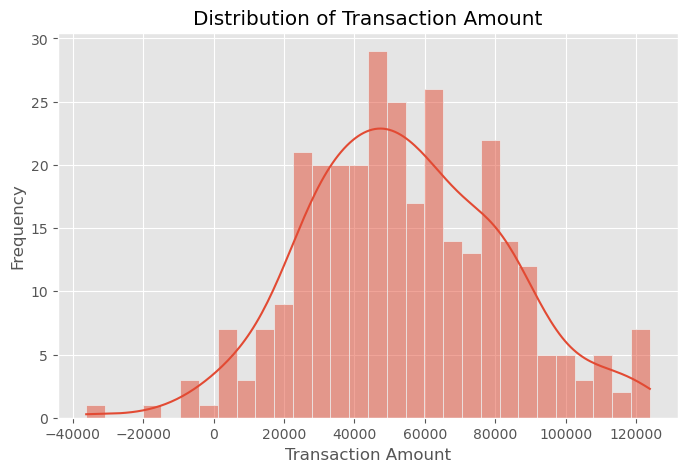

In [97]:
# Transaction Amount Distribution . 


plt.figure(figsize=(8,5))

sns.histplot(df["TransactionAmount"], bins=30, kde=True)

plt.title("Distribution of Transaction Amount")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.show()

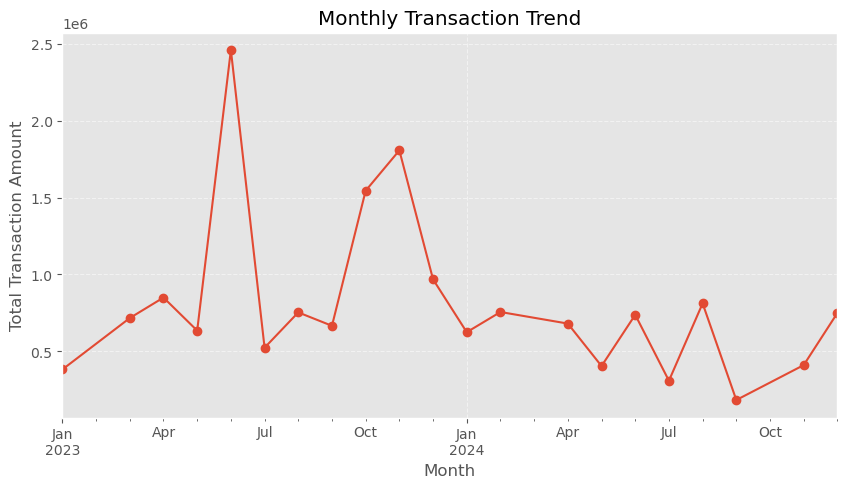

In [98]:
# Monthly Transaction Trend . 


# Convert TransactionDate to datetime
df['TransactionDate'] = pd.to_datetime(df['TransactionDate'])

# Extract Year-Month
df['Month'] = df['TransactionDate'].dt.to_period('M')

# Calculate total transaction amount for each month
monthly = df.groupby('Month')['TransactionAmount'].sum()

# Plot the monthly trend
plt.figure(figsize=(10,5))

monthly.plot(marker='o')

plt.title("Monthly Transaction Trend")
plt.xlabel("Month")
plt.ylabel("Total Transaction Amount")

plt.grid(True, linestyle="--", alpha=0.5)

plt.show()

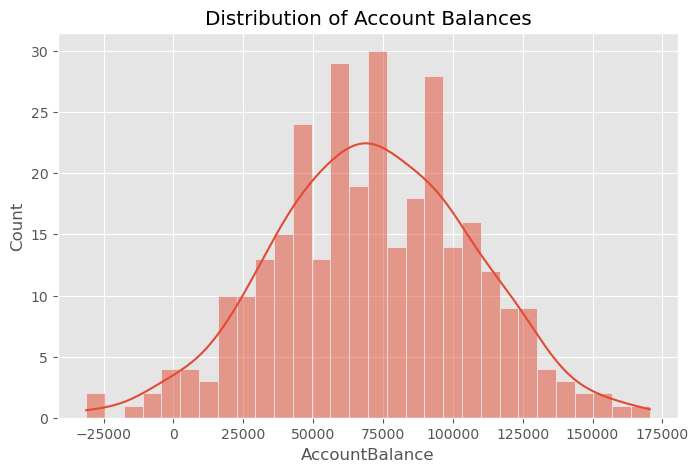

In [99]:
# Account Balance Distribution .  

plt.figure(figsize=(8,5))

sns.histplot(df['AccountBalance'], bins=30, kde=True)

plt.title("Distribution of Account Balances")

plt.show()

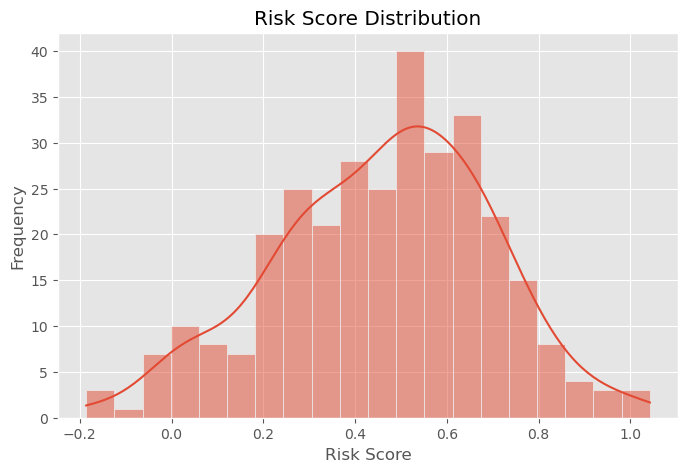

In [100]:
# Risk Score Distribution   . 


plt.figure(figsize=(8,5))

sns.histplot(df["RiskScore"], bins=20, kde=True)

plt.title("Risk Score Distribution")
plt.xlabel("Risk Score")
plt.ylabel("Frequency")

plt.show()

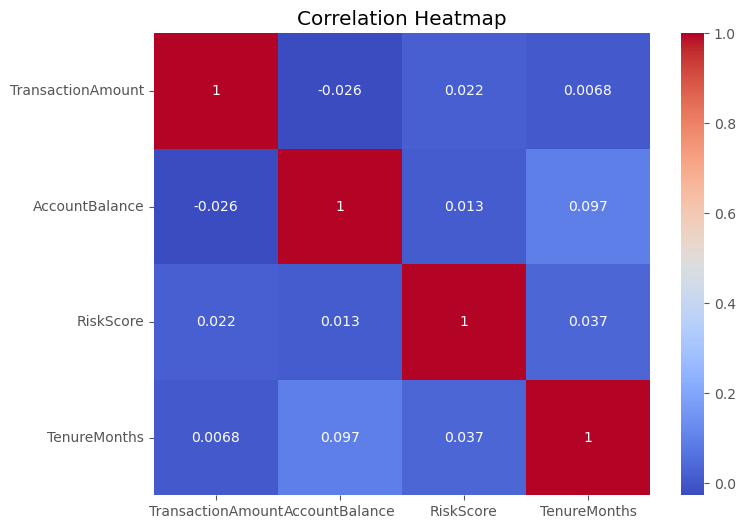

In [101]:
#   Correlation   Heatmap . 

plt.figure(figsize=(8,6))

corr = df[['TransactionAmount','AccountBalance',  'RiskScore',  'TenureMonths']].corr() 
          

sns.heatmap(corr, annot=True,  cmap='coolwarm') 
            
            
plt.title("Correlation Heatmap")

plt.show() 

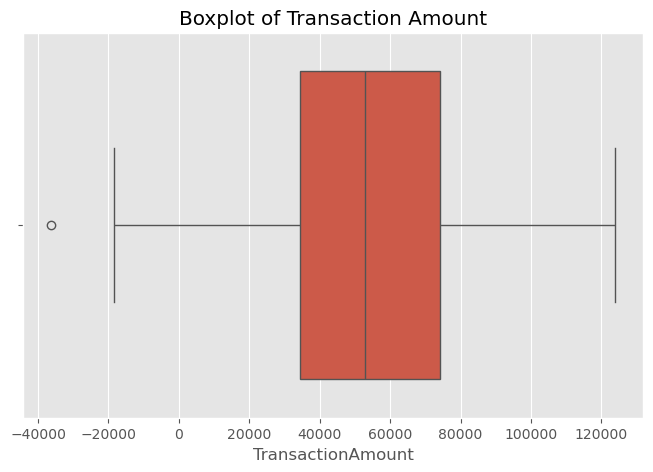

In [102]:
 # Box  plot for outlier detection . 


plt.figure(figsize=(8,5))

sns.boxplot(x=df['TransactionAmount'])

plt.title("Boxplot of Transaction Amount")

plt.show()


# TASK 6 :  Hypothesis test . 

In [103]:
from scipy.stats import ttest_ind

In [104]:
# Create High-Volume and Low-Volume Transaction Groups . 

# ----> High-Volume Transactions → Transaction Amount ≥ Median . 

# -----> Low-Volume Transactions → Transaction Amount < Median .

median_amount = df["TransactionAmount"].median()

high_volume = df[df["TransactionAmount"] >= median_amount]
low_volume = df[df["TransactionAmount"] < median_amount]

print("Median Transaction Amount:", median_amount)
print("High Volume Accounts:", len(high_volume))
print("Low Volume Accounts:", len(low_volume))


Median Transaction Amount: 52884.066745000004
High Volume Accounts: 156
Low Volume Accounts: 156


In [105]:
# Perform Independent Sample t-test . 

t_stat, p_value = ttest_ind( high_volume["AccountBalance"], low_volume["AccountBalance"], equal_var=False)
  

print("T-Statistic :", round(t_stat,3))
print("P-Value :", round(p_value,4))

T-Statistic : -0.238
P-Value : 0.8121


In [108]:
# Decision Rule .

# alpha = 0.05 .

alpha = 0.05

if p_value < 0.05:

    print("Reject the null hypothesis")
else:
    print("Accept Null hypothesis")

Accept Null hypothesis
